In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
base_path = '/glade/work/jonahshaw/PRISM_data/'

# Ocean heat content change across the PRISM cases

Every OHC **time series** under `PRISM_data` lives in `spatial_OHC_data/<family>/`; the other OHC files
(`control_baselines_ocn/`, `spatial_maps_ohc/`) are time-mean maps with no time axis, so they can't be plotted
against time. The processing and plotting functions are in `ohc_cases.py` (this directory).

For each case, the global **total** OHC is `OHC_global_mean × ocean_area_m2` (J, full water column), averaged over
each complete year; the plotted quantity is its change since the run's first year, in ZJ (10²¹ J). Ensembles show the
member mean with the min–max range shaded over the years every member covers; where some members run longer, the
mean of the remaining members continues as a thinner line.

In [3]:
import sys
sys.path.insert(0, "/glade/work/wkamp/GEO/PRISM/PRISM/OHC_levels")
import ohc_cases as oc

assert oc.PRISM_DATA == base_path
plt.rcParams.update(oc.STYLE)

cases = oc.discover_cases(base_path + "spatial_OHC_data/")
overview = (cases.assign(files=cases.files.map(len))
            .groupby(["family", "experiment"], sort=False)
            .agg(members=("member", "count"), files=("files", "sum")))
overview.index = overview.index.set_levels(overview.index.levels[1].map(oc.experiment_label), level=1)
print(f"{len(cases)} cases in {len(overview)} experiments, {int(overview.files.sum())} files")
display(overview)

67 cases in 16 experiments, 701 files


members  files
family                   experiment                                     
ARISE-1.0                SSP245-TSMLT-GAUSS-DELAYED-2045       10    250
                         SSP245-TSMLT-GAUSS-LOWER-0.5          10    350
ARISE_SAI                SSP245-G6-1p5K-SAI                     3      3
                         SSP245-TSMLT-ARISE-EXTENDED            2      3
                         SSP245-TSMLT-GAUSS-DEFAULT            10     10
CESM2_LME                PMIP4-PaleoStrat.850CEcontrol          1     19
                         PMIP4-past1000                         1     20
CESM2_WACCM_1850control  CMIP6-piControl                        1      7
CESM2_WACCM_HIST         CMIP6-historical-WACCM                 3      3
CESM2_WACCM_SSP2-4.5     CMIP6-SSP2-4.5-WACCM                  10     20
CESM2_WACCM_SSP2-4.5_MCB CMIP6-MCB-025PCT                       1      1
                         CMIP6-MCB-050PCT                       1      1
                         CMIP6-MCB-075PCT                       1      1
                         CMIP6-MCB-125PCT                       1      1
                         CMIP6-baseline                         1      1
                         MCB-050PCT                            11     11

## Loading and time-coordinate checks

The files are not uniform, so nothing about their time axes is assumed:

- some cases are one file, others are split across up to 35 files (one per year) and are combined on their
  **decoded** time coordinate with `xr.open_mfdataset` — the files encode time against different reference dates
  ("days since" each file's own start year), which decoding reconciles;
- file names are not trusted: e.g. `CMIP6-MCB-025PCT.000…201501-206912.nc` actually holds 2035–2069;
- every combined case must be an unbroken run of first-of-month `noleap` months with no duplicates
  (`ohc_cases.load_case_total` raises otherwise), and only complete 12-month years enter the annual means;
- a member whose data are identical to another member's is dropped — `MCB-050PCT.e11` is a byte-identical copy of
  member `.011` stored under a second case name, and would otherwise count twice.

Loading all cases takes about a minute and a half.

In [4]:
experiments_by_depth = oc.load_experiments(cases, depth=None)  # (member, ohc_depth, year): every depth bin
experiments = {key: da.sel(ohc_depth=-1) for key, da in experiments_by_depth.items()}  # full water column
summary = oc.summary_table(experiments)
display(summary.style.format({"change_ZJ": "{:+.0f}"}))

  dropped b.e21.BSSP245smbb.f09_g17.MCB-050PCT.e11: identical to member 011


## OHC change by experiment family

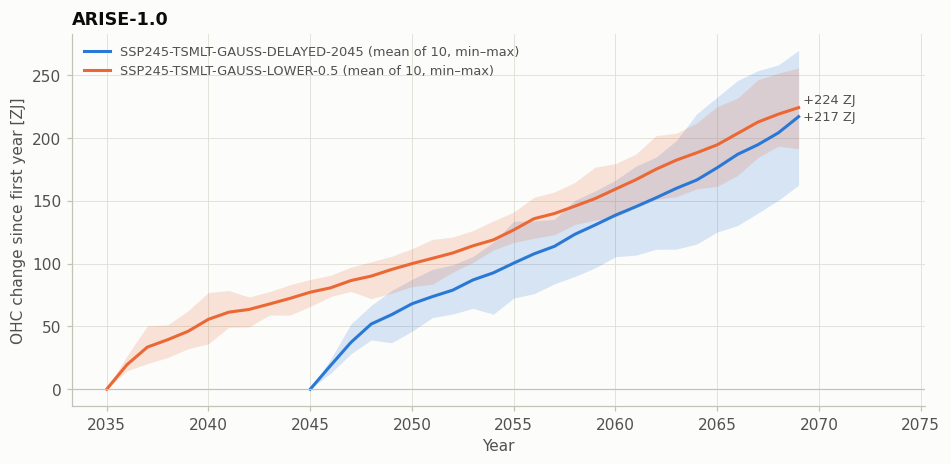

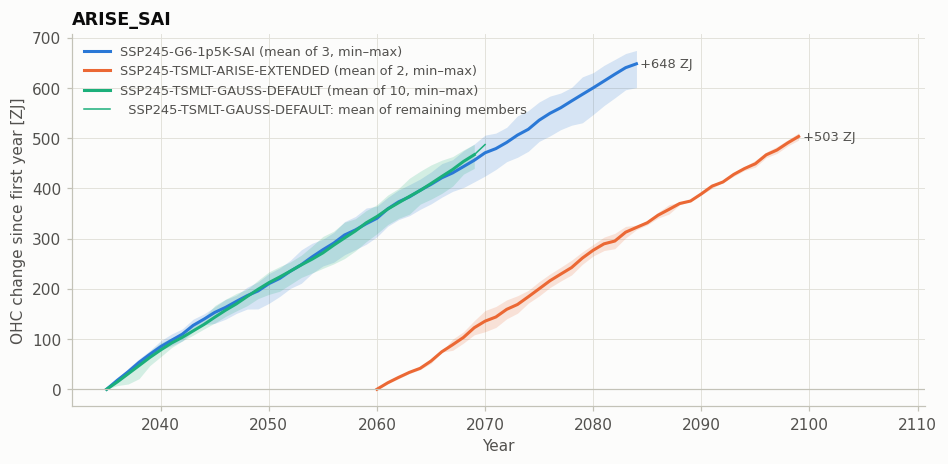

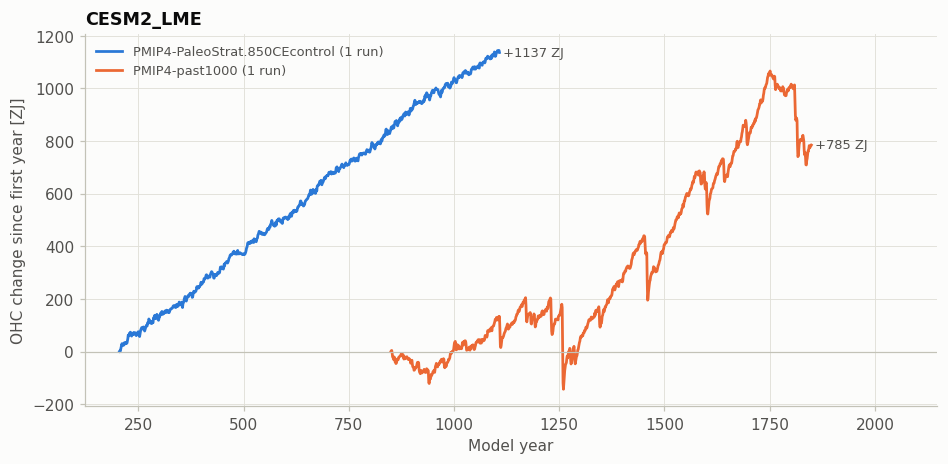

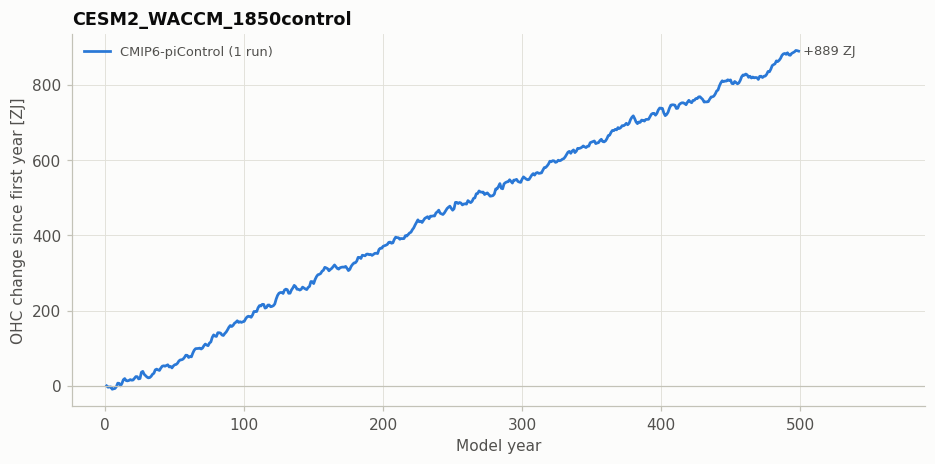

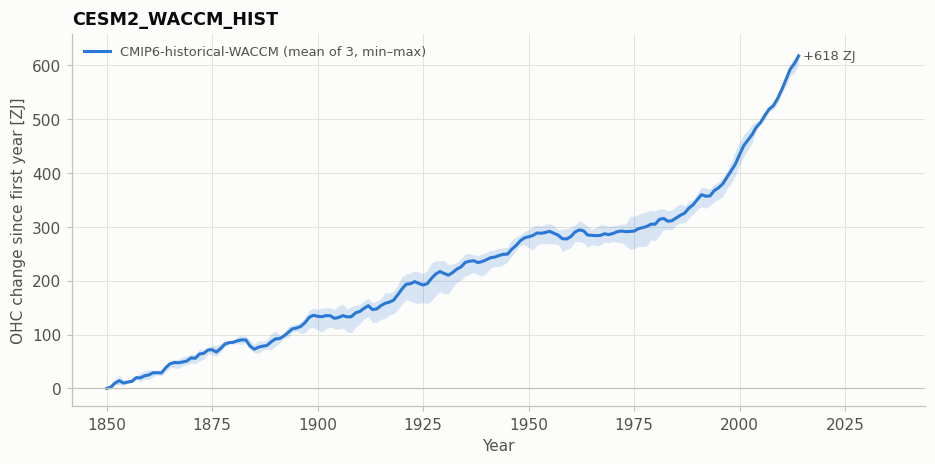

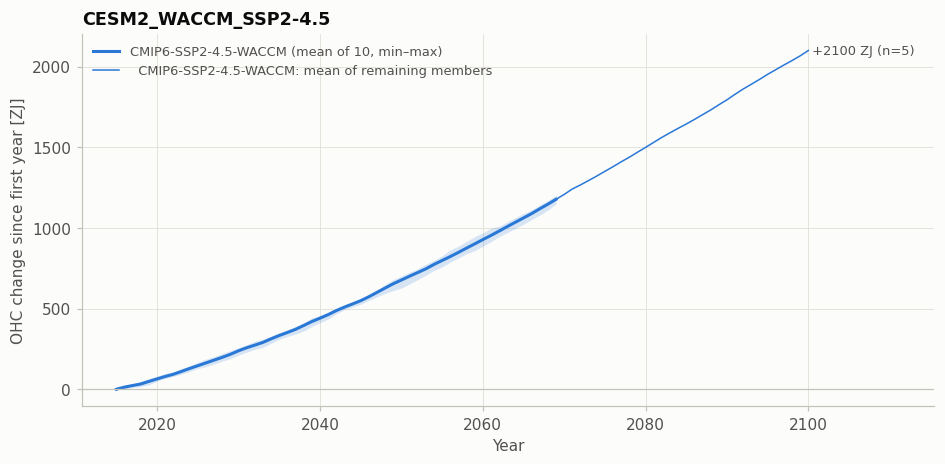

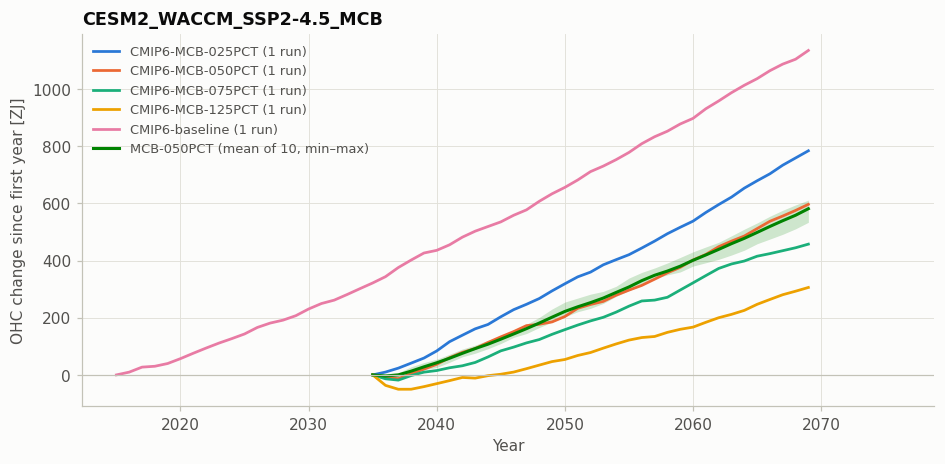

In [5]:
for family in cases["family"].unique():
    fig, ax = plt.subplots(figsize=(10, 4.4))
    oc.plot_family(ax, experiments, family)
    plt.show()

**Reading the plots.** Each curve starts at zero in its own first year, so runs that branch later (e.g. the MCB and
ARISE experiments from 2035, ARISE-EXTENDED from 2060) start from zero later than their parent scenario. To compare
experiments from a shared starting point, re-reference them to a common year, e.g.
`oc.plot_family(ax, experiments, "CESM2_WACCM_SSP2-4.5_MCB", reference_year=2035)`; `per_year=True` plots the
year-to-year change (ZJ/yr) instead of the cumulative change.

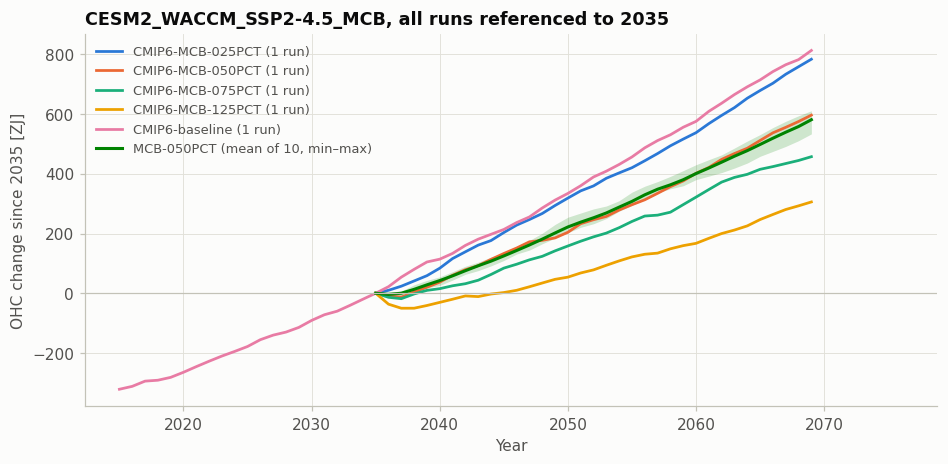

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.4))
oc.plot_family(ax, experiments, "CESM2_WACCM_SSP2-4.5_MCB", reference_year=2035)
ax.set_title("CESM2_WACCM_SSP2-4.5_MCB, all runs referenced to 2035")
plt.show()

## OHC change by depth layer, one figure per experiment

Each figure repeats one experiment's total OHC change (black; for ensembles the member mean, with the members' min–max range of the total as thin gray lines) and shades the part of that change held in each layer of the ocean, shallow (light) to deep (dark). The files store cumulative depth bins (0–300, 0–700, 0–2000 m, full column); the layers are the differences between them (`ohc_cases.layer_changes`). A layer that *loses* heat is stacked below zero, so the total line equals the shaded area above zero minus the shaded area below it.

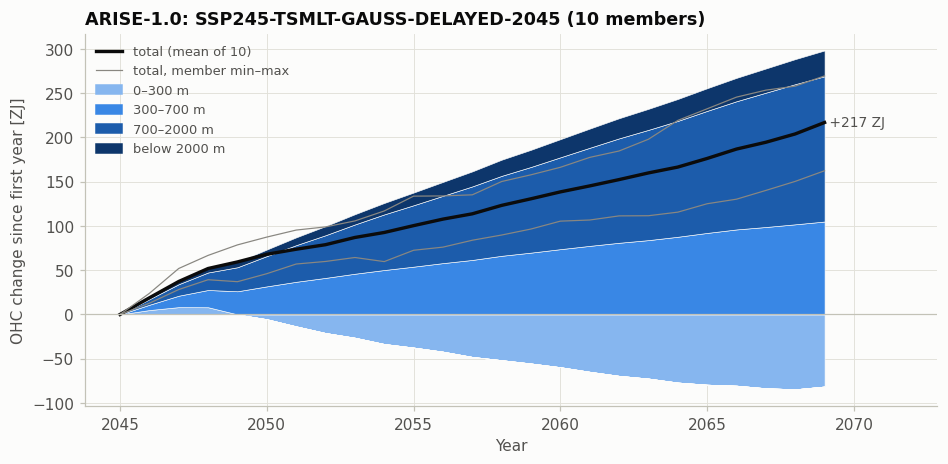

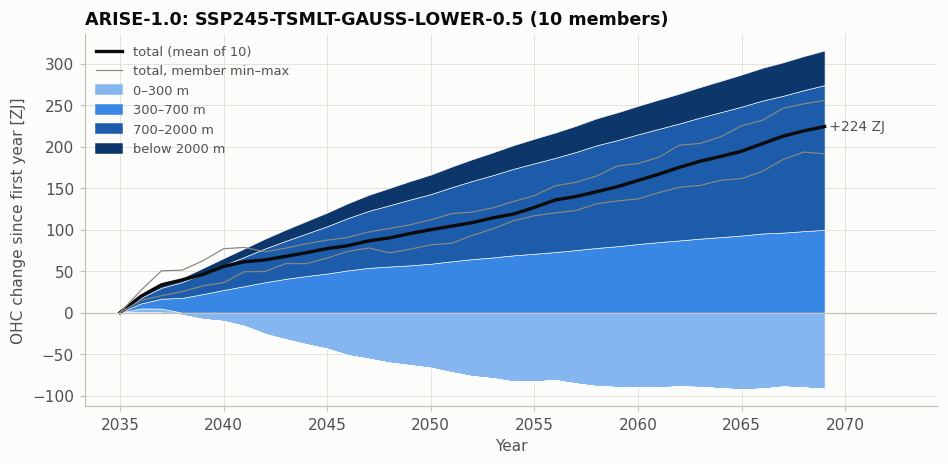

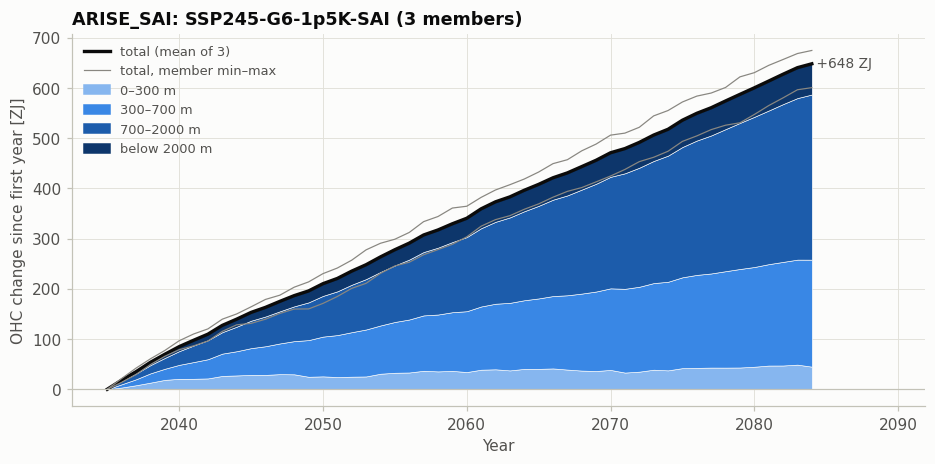

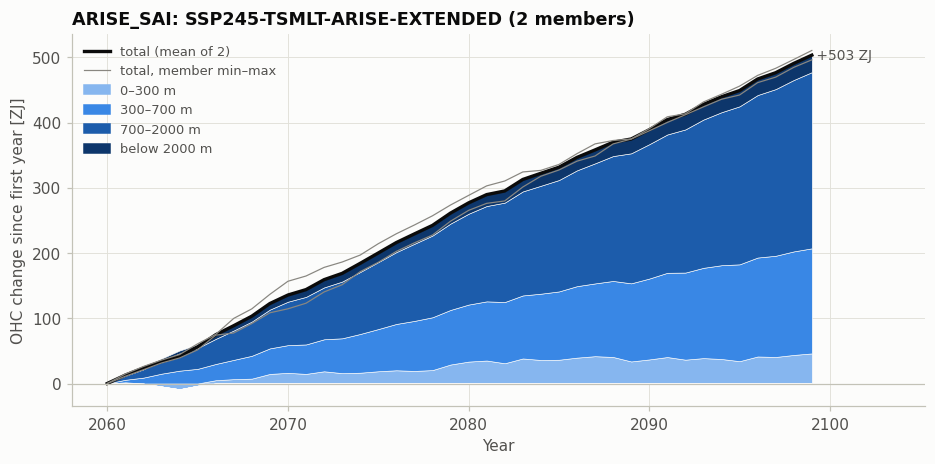

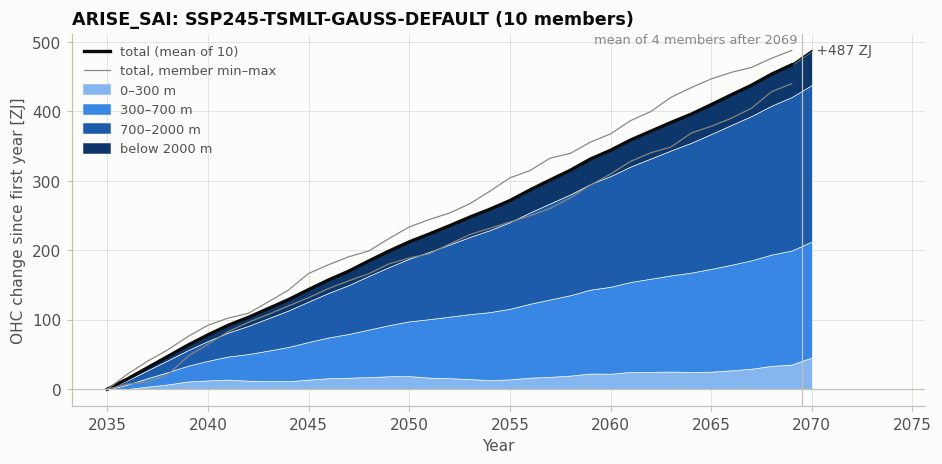

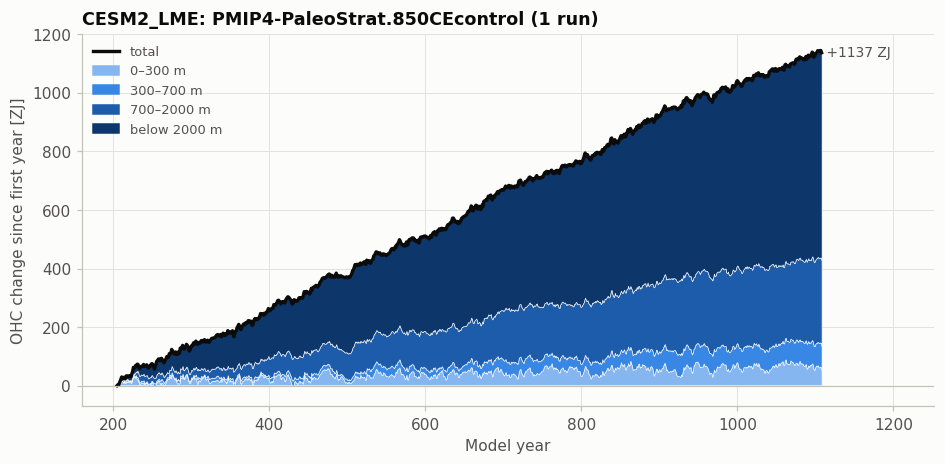

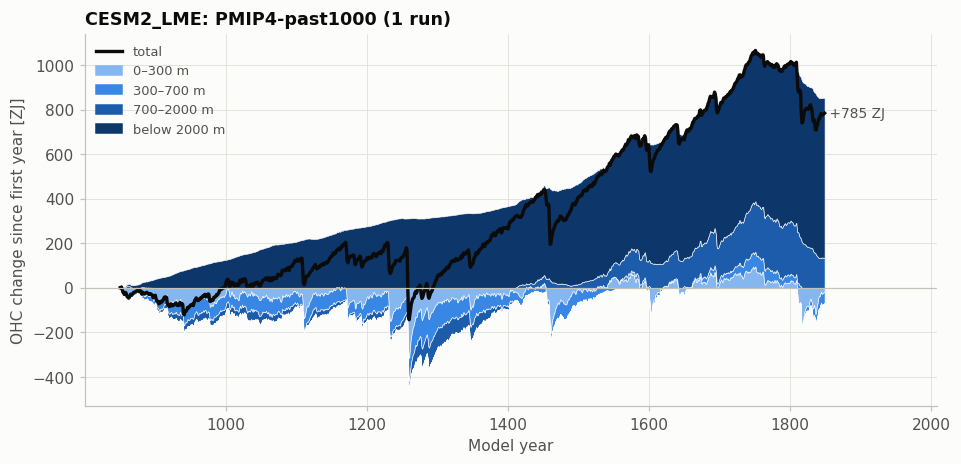

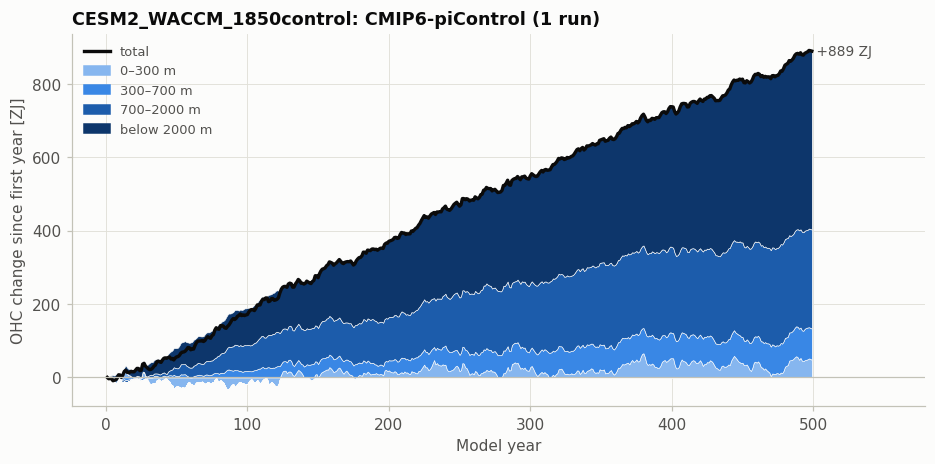

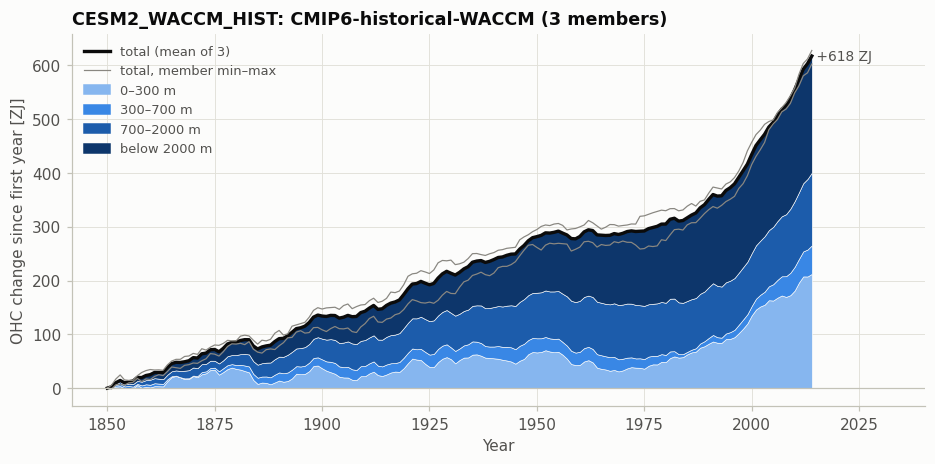

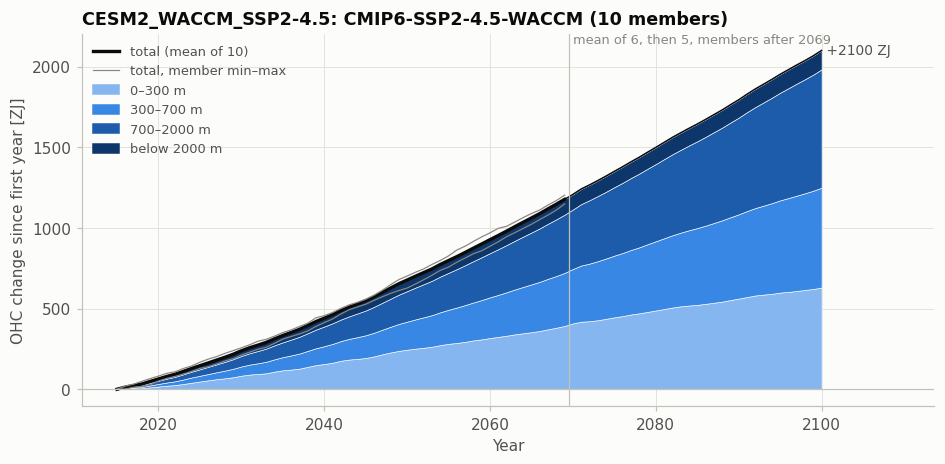

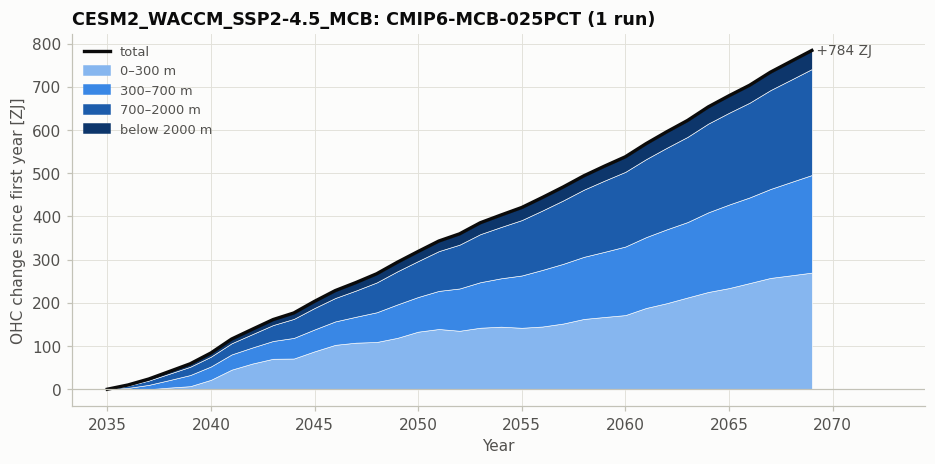

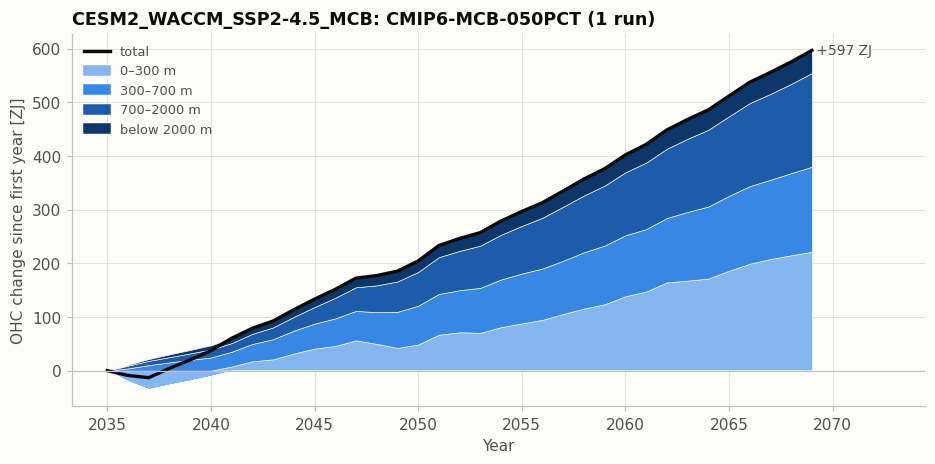

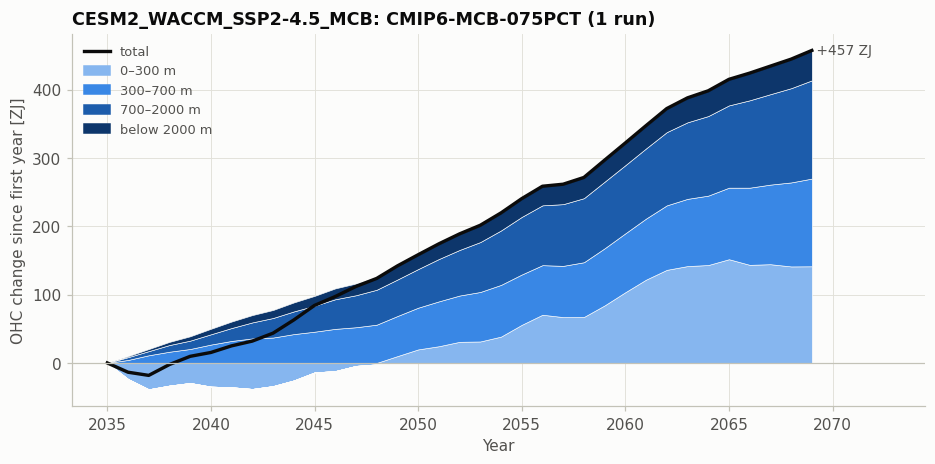

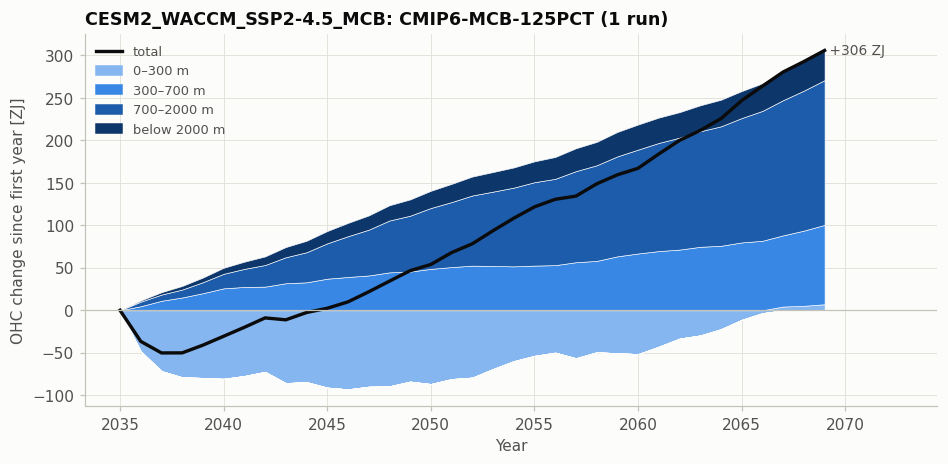

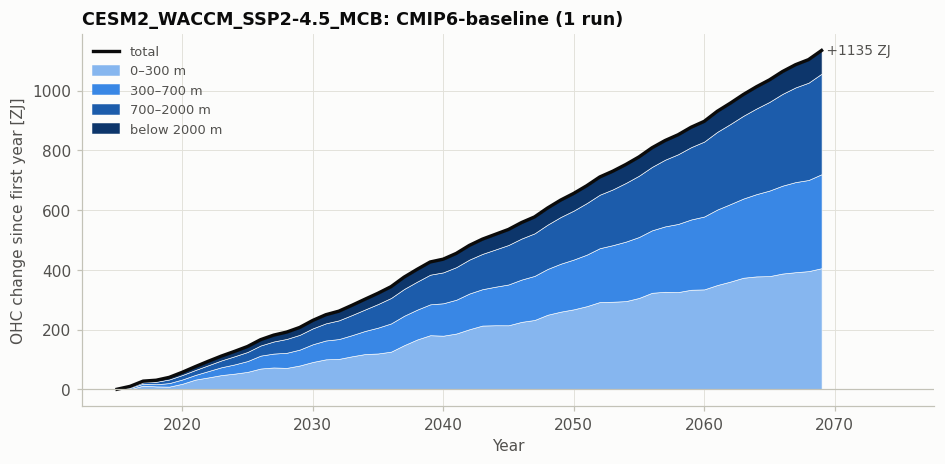

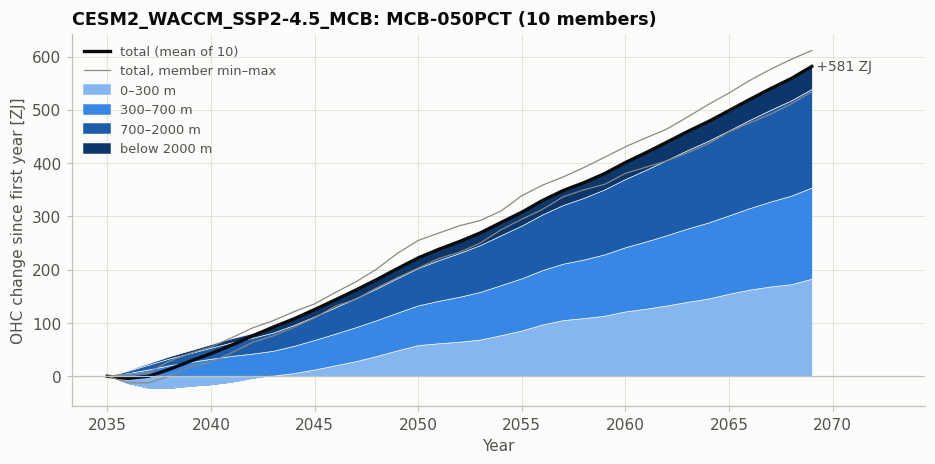

In [7]:
for (family, experiment), da in experiments_by_depth.items():
    fig, ax = plt.subplots(figsize=(10, 4.4))
    oc.plot_layers(ax, da, family, experiment)
    plt.show()

## Maps of OHC change: last 5 years minus first 5 years

For each experiment above, the change in OHC per unit column area (GJ m⁻²) between the mean of its last and first `N_YEARS` years. Ensembles average the members' maps over the first and last years that **every** member covers (so, e.g., SSP2-4.5 ends in 2069, not 2100), using the same members as the plots above (the duplicate `MCB-050PCT.e11` is excluded). Each map is checked on its native POP grid: its ocean-area-weighted mean must equal the change in `OHC_global_mean` over the same years. For plotting, maps are regridded (xESMF, bilinear) from the curvilinear POP grid to a regular 1° grid so they contour without seams, and drawn with cartopy.

Set `MAP_LAYER` below to choose what is mapped: `"total"` (full water column, the default), `"0–300 m"`, `"300–700 m"`, `"700–2000 m"` or `"below 2000 m"`. Each map gets its own color scale (symmetric about zero, spanning the 98th percentile of |change|) unless `MAP_VMAX` sets a shared one.

In [8]:
# --- settings for this section ---
MAP_LAYER = "total"  # "total", "0–300 m", "300–700 m", "700–2000 m" or "below 2000 m"
N_YEARS = 5           # length of the first and last averaging windows, in years
MAP_VMAX = None       # GJ m^-2; None = a separate color scale per map

import cartopy.crs as ccrs

assert MAP_LAYER.replace("-", "–") in oc.MAP_LAYERS, f"MAP_LAYER must be one of {oc.MAP_LAYERS}"

In [9]:
maps = oc.change_maps(cases, experiments_by_depth, n_years=N_YEARS)
map_check = oc.check_change_maps(maps, oc.ocean_cell_area(base_path + "spatial_OHC_data/"))
display(map_check.style.format({"map_mean_GJ_m2": "{:+.4f}", "global_mean_change_GJ_m2": "{:+.4f}", "relative_difference": "{:.1e}"}))
assert (map_check["relative_difference"].abs() < 1e-6).all(), "a map disagrees with its global-mean series"
regridder = oc.make_regridder(next(iter(maps.values())))

  ARISE-1.0                  SSP245-TSMLT-GAUSS-DELAYED-2045    10 member(s): 2065–2069 minus 2045–2049
  ARISE-1.0                  SSP245-TSMLT-GAUSS-LOWER-0.5       10 member(s): 2065–2069 minus 2035–2039
  ARISE_SAI                  SSP245-G6-1p5K-SAI                  3 member(s): 2080–2084 minus 2035–2039
  ARISE_SAI                  SSP245-TSMLT-ARISE-EXTENDED         2 member(s): 2095–2099 minus 2060–2064
  ARISE_SAI                  SSP245-TSMLT-GAUSS-DEFAULT         10 member(s): 2065–2069 minus 2035–2039
  CESM2_LME                  PMIP4-PaleoStrat.850CEcontrol       1 member(s): 1104–1108 minus 205–209
  CESM2_LME                  PMIP4-past1000                      1 member(s): 1845–1849 minus 850–854
  CESM2_WACCM_1850control    CMIP6-piControl                     1 member(s): 495–499 minus 1–5
  CESM2_WACCM_HIST           CMIP6-historical-WACCM              3 member(s): 2010–2014 minus 1850–1854
  CESM2_WACCM_SSP2-4.5       CMIP6-SSP2-4.5-WACCM               10 member(s)

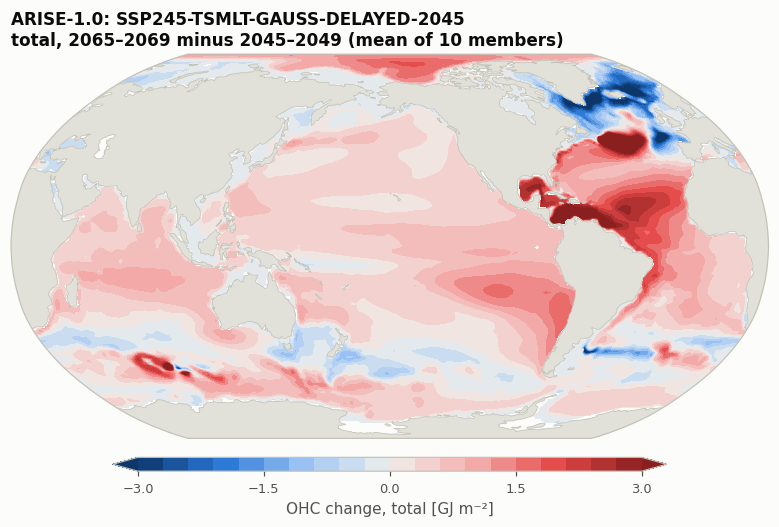

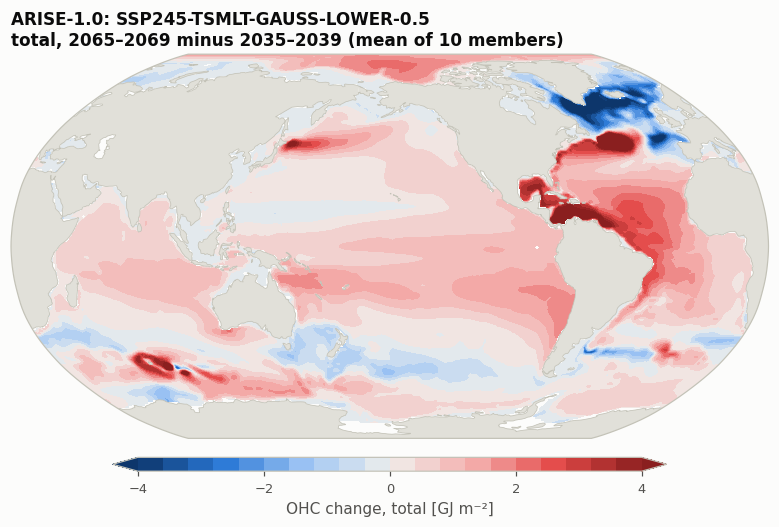

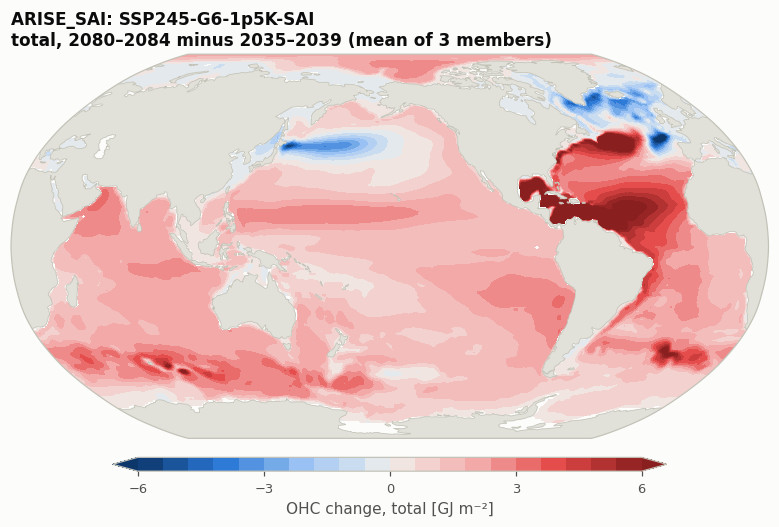

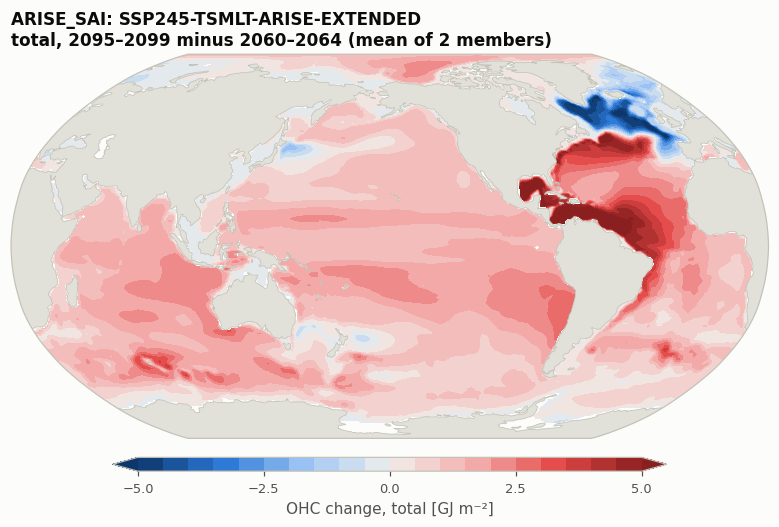

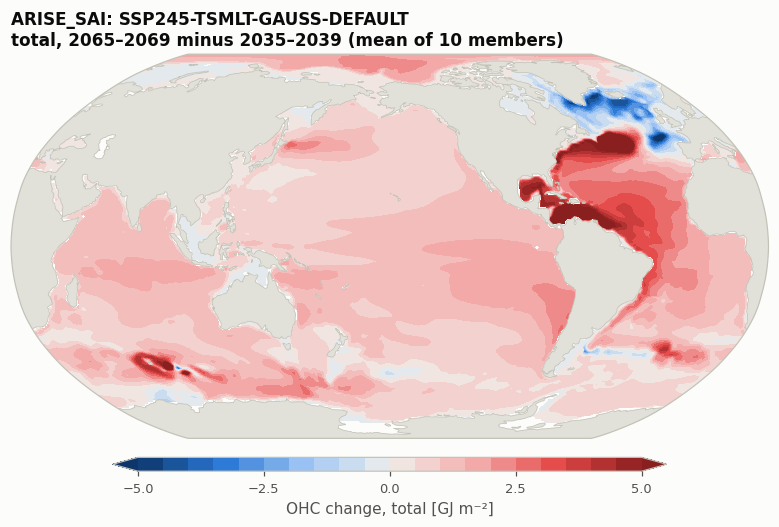

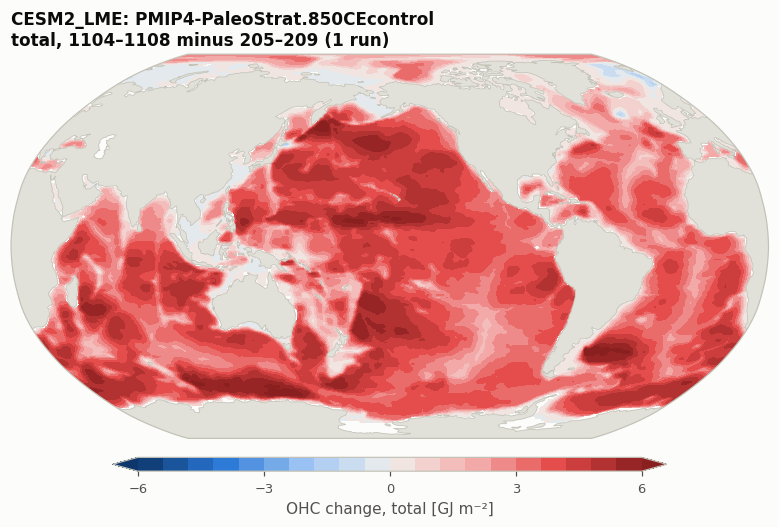

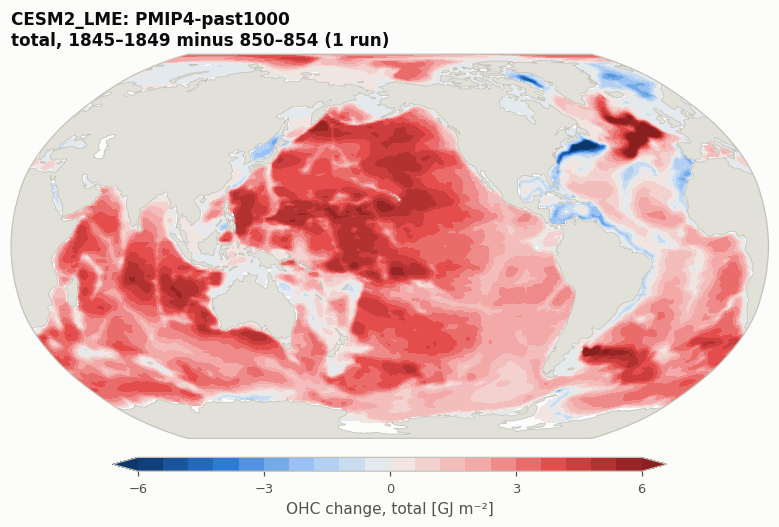

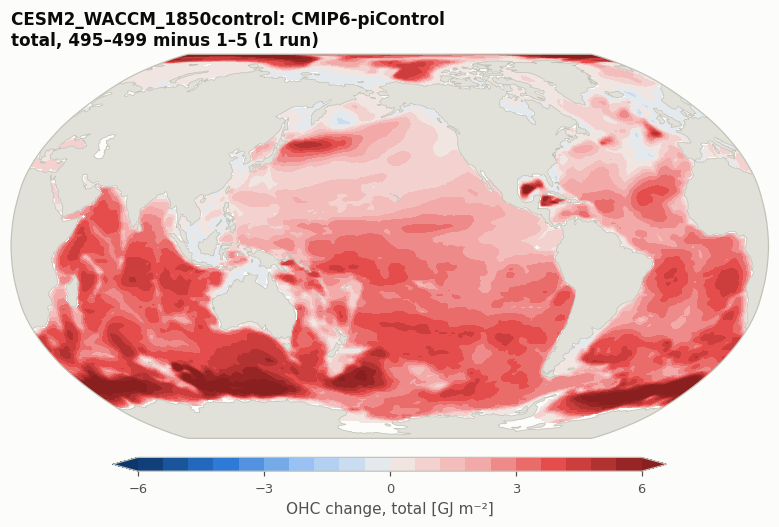

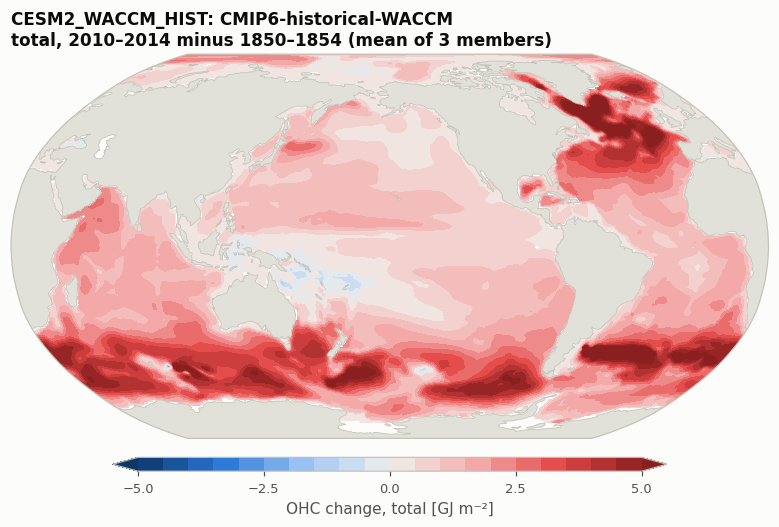

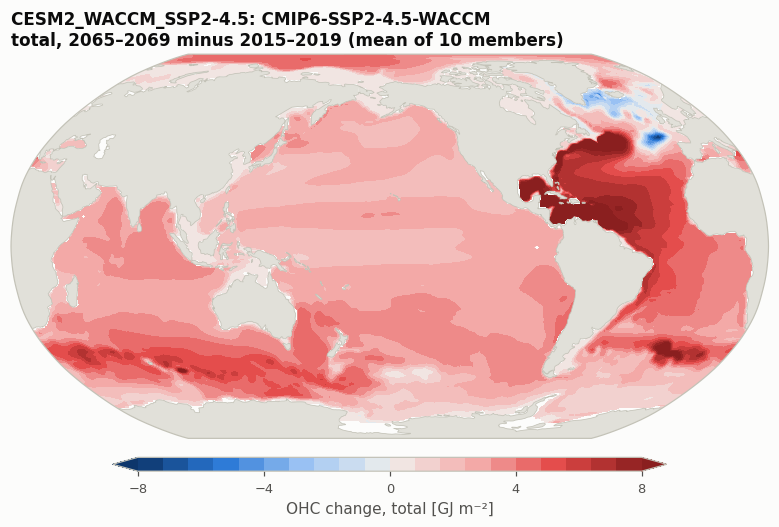

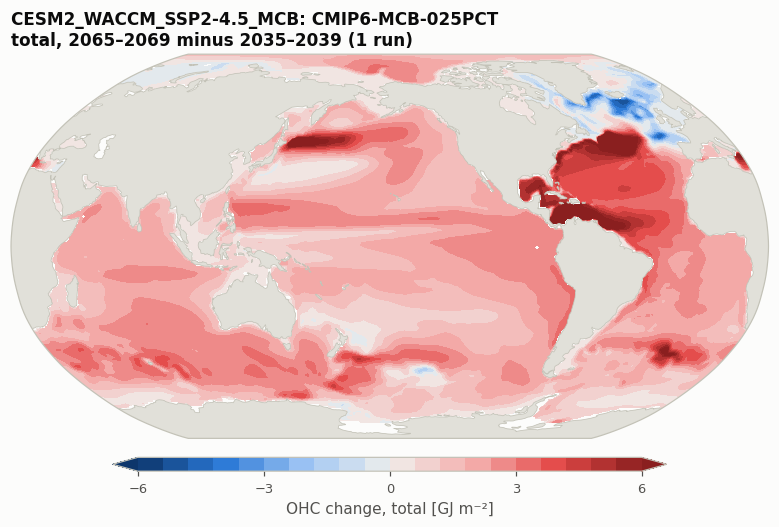

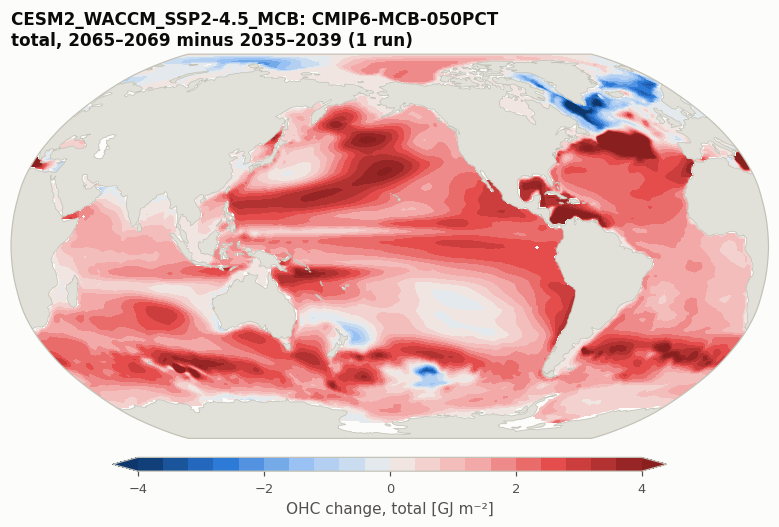

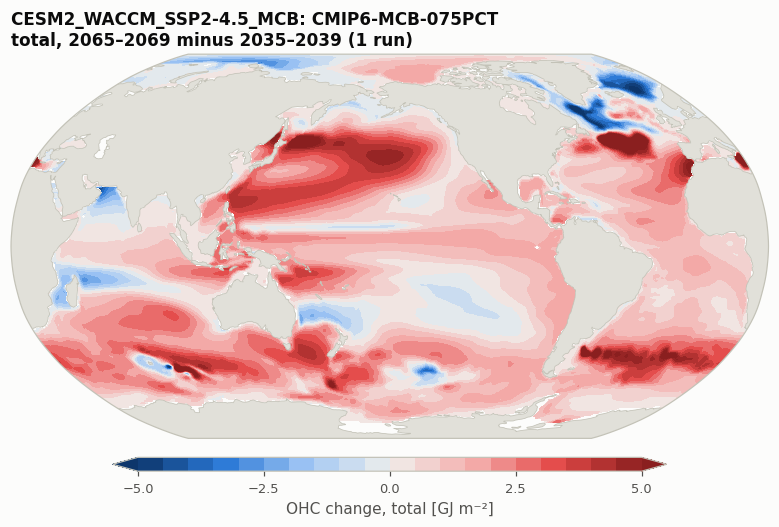

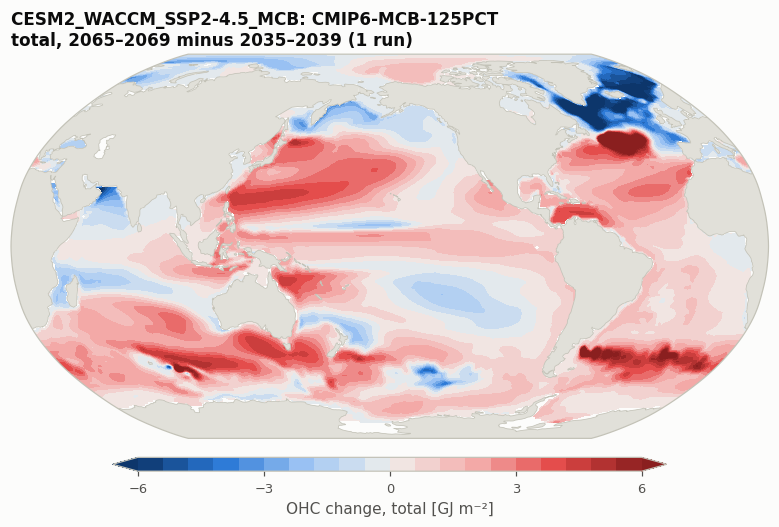

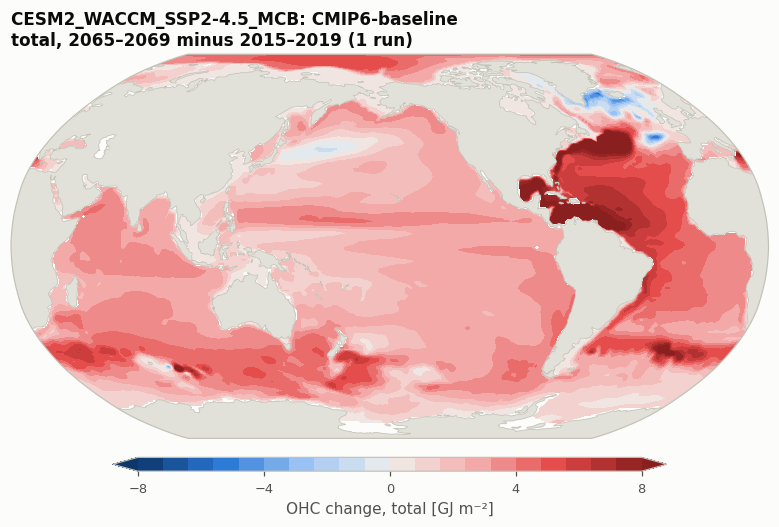

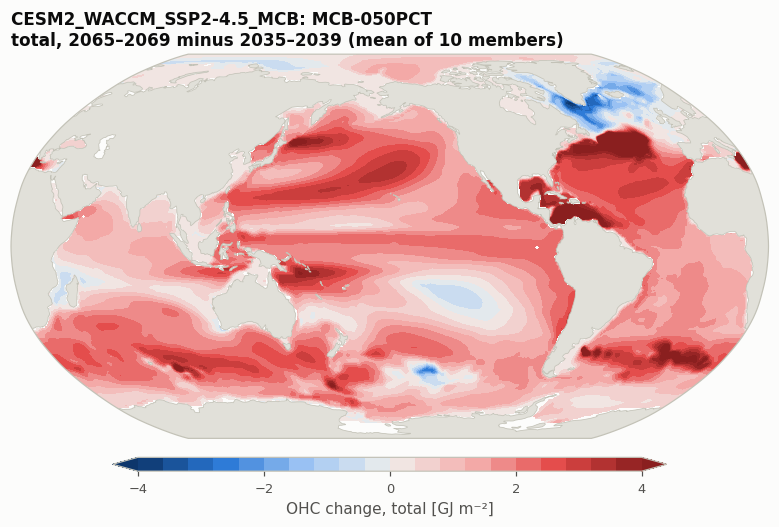

In [10]:
for (family, experiment), change in maps.items():
    fig, ax = plt.subplots(figsize=(10, 5.6), subplot_kw={"projection": ccrs.Robinson(central_longitude=200)})
    oc.plot_change_map(ax, change, regridder, family, experiment, layer=MAP_LAYER, vmax=MAP_VMAX)
    plt.show()

## Maps of OHC in 2065–2069 relative to the 2000–2014 historical mean

The same kind of map as above, but each panel compares a scenario's 2065–2069 mean OHC with a common present-day baseline instead of with its own first years. None of the scenarios cover 2000–2014 (SSP2-4.5 starts in 2015, the ARISE runs in 2035), so the baseline is the **historical ensemble** (`CMIP6-historical-WACCM`, members 001–003) averaged over 2000–2014. Scenario ensembles are member means over 2065–2069; all members of all four cover those years.

Checks: each panel's ocean-area-weighted mean must equal the change in `OHC_global_mean` between the same periods, and the baseline is compared with PRISM's precomputed `control_baselines_ocn/CESM2_WACCM_HIST_2000_2014_OHC.nc`. The four panels share one zero-centered color scale so they can be compared directly. The layer shown follows `MAP_LAYER` (and `MAP_VMAX`) from the map section's settings, or set `DIFF_LAYER` below to override it here.

In [26]:
# --- settings for this section ---
DIFF_LAYER = "total" #MAP_LAYER                 # "total", "0–300 m", "300–700 m", "700–2000 m" or "below 2000 m"
BASELINE = ("CESM2_WACCM_HIST", "CMIP6-historical-WACCM")
BASELINE_YEARS = range(2000, 2015)     # 2000–2014 inclusive
SCENARIO_YEARS = range(2065, 2070)     # 2065–2069 inclusive
SCENARIOS = [                          # panel order: left-to-right, top-to-bottom
    ("ARISE_SAI", "SSP245-TSMLT-GAUSS-DEFAULT"),
    ("ARISE-1.0", "SSP245-TSMLT-GAUSS-LOWER-0.5"),
    ("ARISE_SAI", "SSP245-G6-1p5K-SAI"),
    ("CESM2_WACCM_SSP2-4.5", "CMIP6-SSP2-4.5-WACCM"),
]

assert DIFF_LAYER.replace("-", "–") in oc.MAP_LAYERS, f"DIFF_LAYER must be one of {oc.MAP_LAYERS}"
assert len(SCENARIOS) == 4, "the figure is a 2 x 2 grid"

In [27]:
scenario_keys = [oc.find_experiment(experiments_by_depth, *s) for s in SCENARIOS]
baseline_key = oc.find_experiment(experiments_by_depth, *BASELINE)
diff_maps, baseline = oc.difference_maps(cases, experiments_by_depth, scenario_keys, SCENARIO_YEARS,
                                         baseline_key, BASELINE_YEARS)

diff_check = oc.check_change_maps(diff_maps, oc.ocean_cell_area(base_path + "spatial_OHC_data/"))
display(diff_check.style.format({"map_mean_GJ_m2": "{:+.4f}", "global_mean_change_GJ_m2": "{:+.4f}", "relative_difference": "{:.1e}"}))
assert (diff_check["relative_difference"].abs() < 1e-6).all(), "a map disagrees with its global-mean series"

precomputed = xr.open_dataset(base_path + "control_baselines_ocn/CESM2_WACCM_HIST_2000_2014/"
                              "CESM2_WACCM_HIST_2000_2014_OHC.nc")["OHC"]
max_diff = float(np.nanmax(np.abs(baseline - precomputed))) / oc.GJ
print(f"Baseline vs PRISM's precomputed 2000–2014 baseline: max |difference| = {max_diff:.3f} GJ/m^2. "
      "The precomputed file is a plain mean of the monthly values; this one weights months by length "
      "(the plain mean reproduces the file to float precision).")

,,map_mean_GJ_m2,global_mean_change_GJ_m2,relative_difference
family,experiment,,,
ARISE_SAI,SSP245-TSMLT-GAUSS-DEFAULT,+2.4526,+2.4526,-5.8e-16
ARISE-1.0,SSP245-TSMLT-GAUSS-LOWER-0.5,+1.8135,+1.8135,4.1e-15
ARISE_SAI,SSP245-G6-1p5K-SAI,+2.4282,+2.4282,7.9e-16
CESM2_WACCM_SSP2-4.5,CMIP6-SSP2-4.5-WACCM,+3.4169,+3.4169,2.4e-15


Baseline vs PRISM's precomputed 2000–2014 baseline: max |difference| = 0.033 GJ/m^2. The precomputed file is a plain mean of the monthly values; this one weights months by length (the plain mean reproduces the file to float precision).


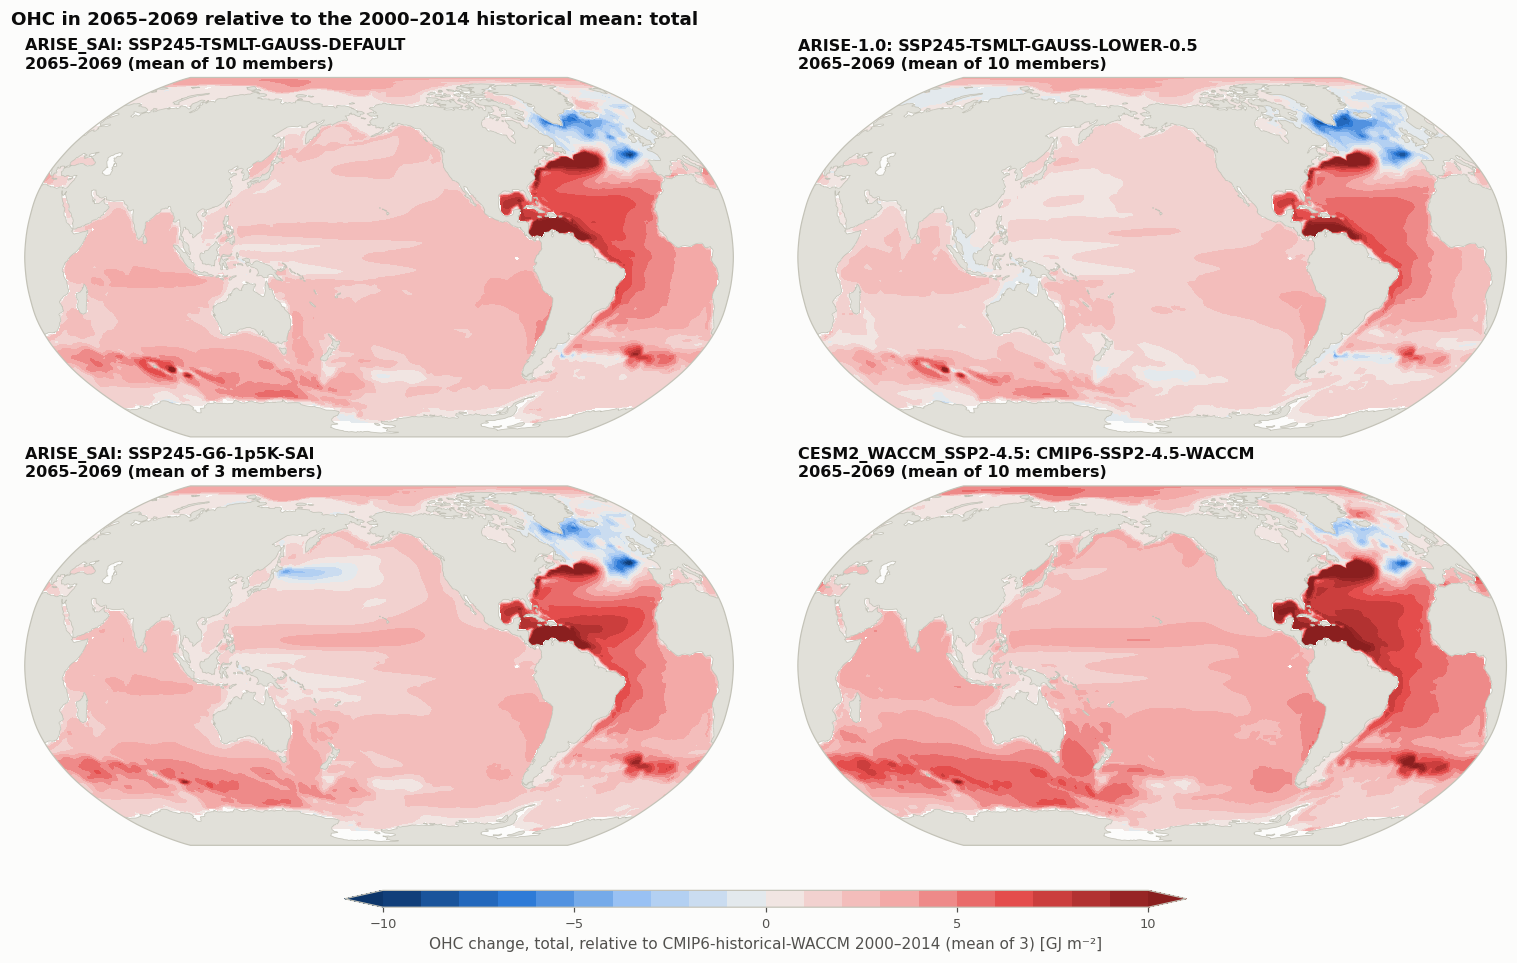

In [28]:
import cartopy.crs as ccrs

fig, axes = plt.subplots(2, 2, figsize=(14, 8.6), layout="constrained",
                         subplot_kw={"projection": ccrs.Robinson(central_longitude=200)})
oc.plot_difference_panels(fig, axes, diff_maps, regridder, layer=DIFF_LAYER, vmax=MAP_VMAX)
fig.suptitle(f"OHC in {SCENARIO_YEARS[0]}–{SCENARIO_YEARS[-1]} relative to the "
             f"{BASELINE_YEARS[0]}–{BASELINE_YEARS[-1]} historical mean: {DIFF_LAYER.replace('-', '–')}",
             x=0.01, ha="left", fontweight="bold", color=oc.INK)
plt.show()

## Maps of SAI scenarios relative to SSP2-4.5, 2065–2069

Like the figure above, but the baseline is the no-intervention scenario at the **same** time: each panel is an ARISE scenario's 2065–2069 mean OHC minus the SSP2-4.5 2065–2069 mean (all three are member means over 2065–2069; every member covers those years). Blue means the ocean holds less heat with stratospheric aerosol injection than without it. The same checks apply, and the layer follows `DIFF_LAYER` from the section above unless `SAI_LAYER` is set below.

In [29]:
# --- settings for this section ---
SAI_LAYER = DIFF_LAYER                      # "total", "0–300 m", "300–700 m", "700–2000 m" or "below 2000 m"
SAI_BASELINE = ("CESM2_WACCM_SSP2-4.5", "CMIP6-SSP2-4.5-WACCM")
SAI_YEARS = range(2065, 2070)               # used for the scenarios and the baseline
SAI_SCENARIOS = [
    ("ARISE_SAI", "SSP245-TSMLT-GAUSS-DEFAULT"),
    ("ARISE-1.0", "SSP245-TSMLT-GAUSS-LOWER-0.5"),
]

assert SAI_LAYER.replace("-", "–") in oc.MAP_LAYERS, f"SAI_LAYER must be one of {oc.MAP_LAYERS}"

sai_maps, sai_baseline = oc.difference_maps(
    cases, experiments_by_depth, [oc.find_experiment(experiments_by_depth, *s) for s in SAI_SCENARIOS], SAI_YEARS,
    oc.find_experiment(experiments_by_depth, *SAI_BASELINE), SAI_YEARS)
sai_check = oc.check_change_maps(sai_maps, oc.ocean_cell_area(base_path + "spatial_OHC_data/"))
display(sai_check.style.format({"map_mean_GJ_m2": "{:+.4f}", "global_mean_change_GJ_m2": "{:+.4f}", "relative_difference": "{:.1e}"}))
assert (sai_check["relative_difference"].abs() < 1e-6).all(), "a map disagrees with its global-mean series"

,,map_mean_GJ_m2,global_mean_change_GJ_m2,relative_difference
family,experiment,,,
ARISE_SAI,SSP245-TSMLT-GAUSS-DEFAULT,-0.9642,-0.9642,-1.0e-14
ARISE-1.0,SSP245-TSMLT-GAUSS-LOWER-0.5,-1.6034,-1.6034,1.5e-16


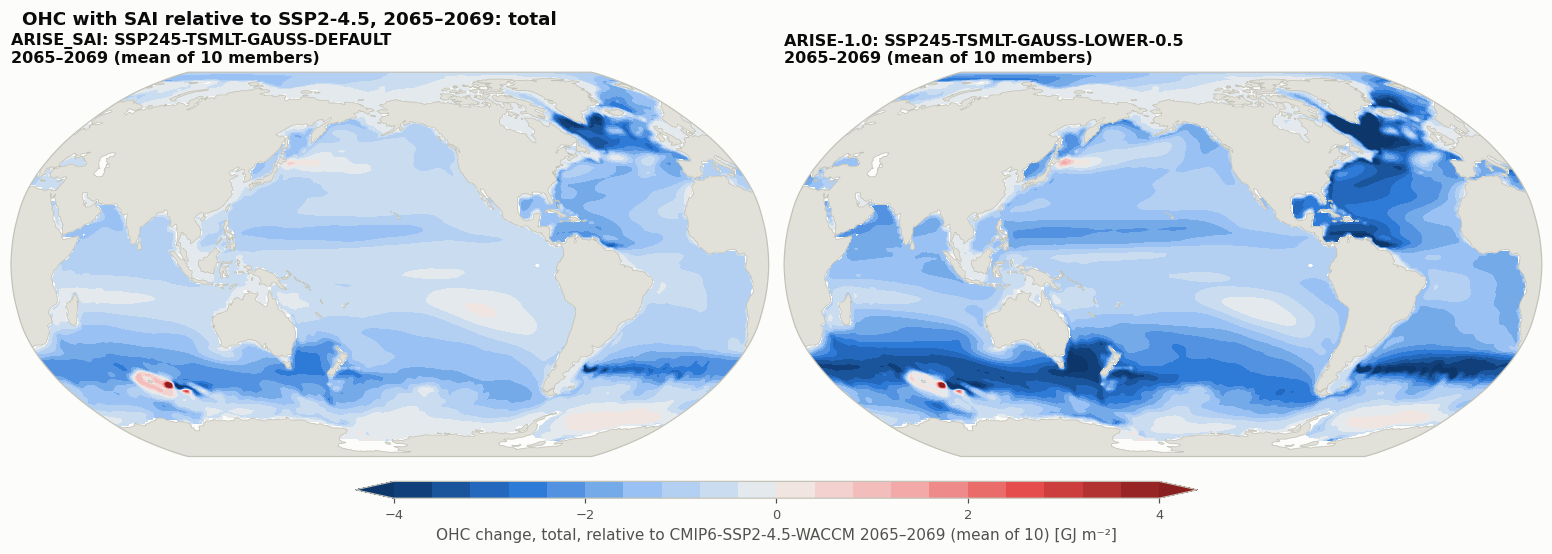

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), layout="constrained",
                         subplot_kw={"projection": ccrs.Robinson(central_longitude=200)})
oc.plot_difference_panels(fig, axes, sai_maps, regridder, layer=SAI_LAYER, vmax=MAP_VMAX)
fig.suptitle(f"OHC with SAI relative to SSP2-4.5, {SAI_YEARS[0]}–{SAI_YEARS[-1]}: "
             f"{SAI_LAYER.replace('-', '–')}", x=0.01, ha="left", fontweight="bold", color=oc.INK)
plt.show()